# Random Map Generation

Robot beacon localization project — Step 1: random map generation.

**Project rules recap**

- The map is built from grid cells: the selected cells are free space, and the map's outer boundary and the boundaries of unselected cells are all walls
- The free space must be fully connected (no isolated regions)
- Beacons must be placed on walls (anywhere along a wall segment, not only at lattice points)
- The robot can be anywhere in the free space and must see ≥3 beacons at the same time to localize (collinear beacons also count)
- Lines of sight cannot pass through walls

This notebook implements: **growth-based map generation → hole carving → connectivity guarantee → wall segment extraction and merging → beacon candidates (wall corners + the midpoint of every wall segment) → visualization**.

In [1]:
import random
from collections import deque
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ---------------- parameters ----------------
GRID_W, GRID_H = 16, 12   # grid size (in cells)
TARGET_CELLS  = 120       # map area (number of free cells, before carving holes)
HOLE_CELLS    = 10        # number of interior cells to try to carve out (forming holes/obstacles)
SEED          = 42        # random seed, for reproducibility

## 1. Growth-based map generation

Start from a seed cell and repeatedly add a random cell that is 4-adjacent to the selected region, until the target area is reached.
Free space generated this way is **connected by construction**, with an irregular shape and reflex corners.

In [2]:
def neighbors(c):
    x, y = c
    return [(x + 1, y), (x - 1, y), (x, y + 1), (x, y - 1)]


def grow_map(w, h, target, rng):
    """Growth method: return the set of free cells; each cell (x, y) occupies the square [x,x+1]×[y,y+1]"""
    target = min(target, w * h)
    start = (w // 2, h // 2)
    cells = {start}
    frontier = {n for n in neighbors(start) if 0 <= n[0] < w and 0 <= n[1] < h}
    while len(cells) < target and frontier:
        c = rng.choice(sorted(frontier))
        frontier.discard(c)
        cells.add(c)
        for n in neighbors(c):
            if 0 <= n[0] < w and 0 <= n[1] < h and n not in cells:
                frontier.add(n)
    return cells


def is_connected(cells):
    """BFS check that the free space is 4-connected"""
    if not cells:
        return False
    start = next(iter(cells))
    seen, dq = {start}, deque([start])
    while dq:
        for n in neighbors(dq.popleft()):
            if n in cells and n not in seen:
                seen.add(n)
                dq.append(n)
    return len(seen) == len(cells)

## 2. Carving holes

Maps from pure growth tend to be "blocky". We randomly remove some **interior** cells to form enclosed obstacles (holes);
the edges of a hole are walls too, so beacons can be placed on them. After every removal we check that the remaining free space is still connected, and skip the cell otherwise.
With 70% probability the next cell is taken next to an already-carved area, so holes form clumps rather than scattered dots.

In [3]:
def carve_holes(cells, n_holes, rng):
    """Remove up to n_holes interior cells to form holes, keeping the free space connected"""
    cells, removed = set(cells), set()
    attempts = 0
    while len(removed) < n_holes and attempts < n_holes * 30:
        attempts += 1
        # interior cells: all four neighbors are in (free space ∪ carved area), so holes never touch the outer boundary
        interior = [c for c in cells
                    if all(nb in cells or nb in removed for nb in neighbors(c))]
        if not interior:
            break
        adj = [c for c in interior if any(nb in removed for nb in neighbors(c))]
        pool = adj if adj and rng.random() < 0.7 else interior
        c = rng.choice(sorted(pool))
        if len(cells) > 1 and is_connected(cells - {c}):
            cells.discard(c)
            removed.add(c)
    return cells

## 3. Wall segment extraction and merging

Every cell edge between a free cell and a non-free cell (including outside the map) is a unit wall.
Collinear unit walls that connect end to end are merged into long wall segments, giving the map's wall geometry for the later visibility computation and beacon placement.

In [4]:
def extract_wall_edges(cells):
    """Return all unit wall edges, each as ((x1,y1),(x2,y2)), with lattice-point endpoints"""
    edges = []
    for (x, y) in cells:
        if (x, y - 1) not in cells: edges.append(((x, y), (x + 1, y)))          # bottom
        if (x, y + 1) not in cells: edges.append(((x, y + 1), (x + 1, y + 1)))  # top
        if (x - 1, y) not in cells: edges.append(((x, y), (x, y + 1)))          # left
        if (x + 1, y) not in cells: edges.append(((x + 1, y), (x + 1, y + 1)))  # right
    return edges


def _merge_intervals(ivs):
    ivs = sorted(ivs)
    out = [list(ivs[0])]
    for a, b in ivs[1:]:
        if a == out[-1][1]:
            out[-1][1] = b
        else:
            out.append([a, b])
    return out


def merge_edges(edges):
    """Collinear, connected unit walls → long wall segments"""
    horiz, vert = {}, {}
    for p1, p2 in edges:
        if p1[1] == p2[1]:
            horiz.setdefault(p1[1], []).append((min(p1[0], p2[0]), max(p1[0], p2[0])))
        else:
            vert.setdefault(p1[0], []).append((min(p1[1], p2[1]), max(p1[1], p2[1])))
    segments = []
    for y, ivs in horiz.items():
        segments += [((a, y), (b, y)) for a, b in _merge_intervals(ivs)]
    for x, ivs in vert.items():
        segments += [((x, a), (x, b)) for a, b in _merge_intervals(ivs)]
    return segments

## 4. Beacon candidates

Beacons can go anywhere on a wall, but the optimization needs a finite candidate set. We take:

- **Wall corners** (all wall-segment endpoints, including T-junctions) — reflex corners have the best visibility and are the theoretically preferred positions
- **The midpoint of every wall segment** — adds coverage along the middle of long straight walls

In [5]:
def beacon_candidates(segments):
    """Return (list of corners, list of midpoints)"""
    corners = set()
    mids = []
    for p1, p2 in segments:
        corners.add(p1)
        corners.add(p2)
        mids.append(((p1[0] + p2[0]) / 2, (p1[1] + p2[1]) / 2))
    return sorted(corners), mids


def make_map(w, h, target, holes, seed):
    """Full pipeline: generate map → carve holes → wall segments → candidates"""
    rng = random.Random(seed)
    cells = grow_map(w, h, target, rng)
    cells = carve_holes(cells, holes, rng)
    assert is_connected(cells), 'free space must be connected'
    segments = merge_edges(extract_wall_edges(cells))
    corners, mids = beacon_candidates(segments)
    return cells, segments, corners, mids

## 5. Visualization

Light blue = free space, black lines = walls, red dots = corner candidates, orange squares = wall-midpoint candidates.

free cells: 110   wall segments: 72   candidates: 72 corners + 72 midpoints = 144


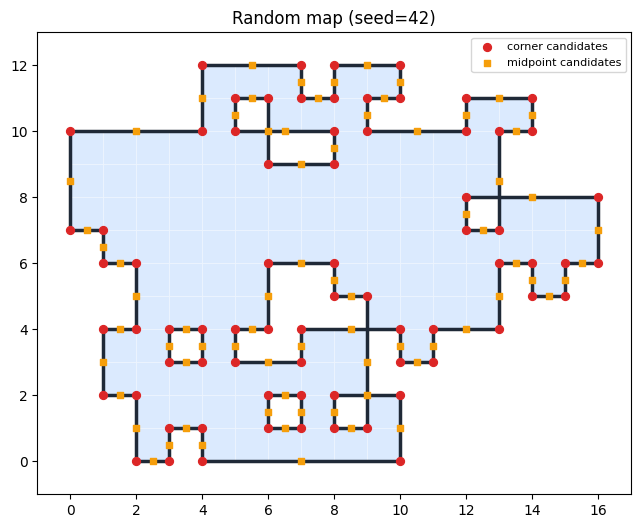

In [6]:
def plot_map(cells, segments=None, corners=None, mids=None, ax=None, title=''):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))
    for (x, y) in cells:
        ax.add_patch(Rectangle((x, y), 1, 1, facecolor='#dbeafe',
                               edgecolor='#eff6ff', linewidth=0.5))
    if segments:
        for (x1, y1), (x2, y2) in segments:
            ax.plot([x1, x2], [y1, y2], color='#1f2937',
                    linewidth=2.5, solid_capstyle='round')
    if corners:
        xs, ys = zip(*corners)
        ax.scatter(xs, ys, s=32, color='#dc2626', zorder=3, label='corner candidates')
    if mids:
        xs, ys = zip(*mids)
        ax.scatter(xs, ys, s=20, color='#f59e0b', marker='s',
                   zorder=3, label='midpoint candidates')
    xs = [x for x, _ in cells]
    ys = [y for _, y in cells]
    ax.set_xlim(min(xs) - 1, max(xs) + 2)
    ax.set_ylim(min(ys) - 1, max(ys) + 2)
    ax.set_aspect('equal')
    ax.set_title(title)
    if corners or mids:
        ax.legend(loc='upper right', fontsize=8)
    return ax


cells, segments, corners, mids = make_map(GRID_W, GRID_H, TARGET_CELLS, HOLE_CELLS, SEED)
print(f'free cells: {len(cells)}   wall segments: {len(segments)}   '
      f'candidates: {len(corners)} corners + {len(mids)} midpoints = {len(corners) + len(mids)}')
plot_map(cells, segments, corners, mids, title=f'Random map (seed={SEED})')
plt.show()

## 6. Multiple random maps

Use different seeds to check that the generator produces diverse, connected maps.

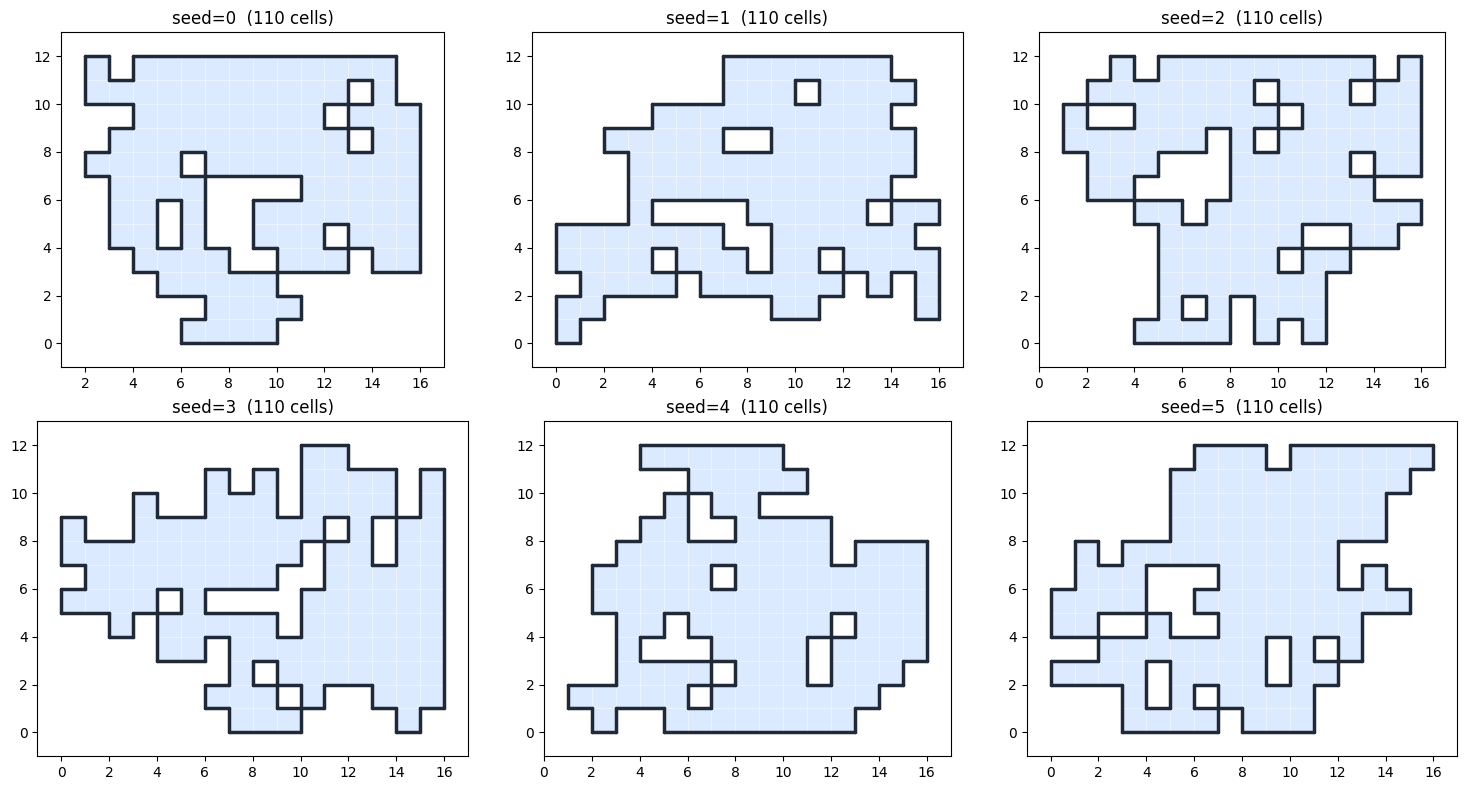

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for seed, ax in enumerate(axes.flat):
    c, s, _, _ = make_map(GRID_W, GRID_H, TARGET_CELLS, HOLE_CELLS, seed)
    plot_map(c, s, ax=ax, title=f'seed={seed}  ({len(c)} cells)')
plt.tight_layout()
plt.show()

## Next steps

1. **Visibility computation**: whether a point-to-point line of sight passes through a wall (segment intersection test), and the visible region of each candidate beacon
2. **Coverage verification**: sample the free space (cell centers or finer) and verify that every position sees ≥3 beacons
3. **Optimization**: greedy multi-cover to minimize the number of beacons, with ILP on small maps as an optimal baseline